TODO:
- Response ID tracking
- Perform edits with structured output
- Validated list tracking
- Switch from error to limitations
- Redefine sentence extraction

Generation:
- Change to storing results, not pydantic objects
- Prevent data loss in dill storage

In [1]:
import json
import random
import base64
import os
import shutil
import subprocess
import dill
import nltk
import itertools
import config
import taxonomy
import datetime
from nltk.tokenize import sent_tokenize
from openai import OpenAI
from pydantic import BaseModel
from openai.lib._pydantic import to_strict_json_schema
from utils.DataHandlers import LatexDataHandler
from utils.ModelClient import ModelClient
from pathlib import Path
from collections import Counter
from pylatexenc.latexwalker import LatexWalker, LatexMacroNode, LatexGroupNode
from pylatexenc.latex2text import LatexNodes2Text
from IPython.display import Image


In [2]:
data_handler = LatexDataHandler(config.DATA_FOLDER_PATH)

# Setup

In [3]:
OUTPUT_FOLDER_PATH = config.OUTPUT_FOLDER_PATH
WORKSPACE_FOLDER_PATH = config.WORKSPACE_FOLDER_PATH
RESULTS_FOLDER_PATH = config.RESULTS_FOLDER_PATH
EDIT_MODEL = config.EDIT_MODEL_INFO[2]

instance_id = datetime.datetime.now().strftime("%Y_%m_%d_%H_%M_%S")
BACKUP_FOLDER_PATH = f'backups/'
if not os.path.exists(BACKUP_FOLDER_PATH):
    os.makedirs(BACKUP_FOLDER_PATH)

if os.path.exists(OUTPUT_FOLDER_PATH) or os.path.exists(WORKSPACE_FOLDER_PATH) or os.path.exists(RESULTS_FOLDER_PATH):
    BACKUP_FOLDER_PATH = f'backups/backup_{instance_id}/'
    os.makedirs(BACKUP_FOLDER_PATH)

    if os.path.exists(OUTPUT_FOLDER_PATH):
        shutil.move(OUTPUT_FOLDER_PATH, BACKUP_FOLDER_PATH + OUTPUT_FOLDER_PATH)
    if os.path.exists(WORKSPACE_FOLDER_PATH):
        shutil.move(WORKSPACE_FOLDER_PATH, BACKUP_FOLDER_PATH + WORKSPACE_FOLDER_PATH)
    if os.path.exists(RESULTS_FOLDER_PATH):
        shutil.move(RESULTS_FOLDER_PATH, BACKUP_FOLDER_PATH + RESULTS_FOLDER_PATH)

# Dataset Construction

In [4]:
#subprocess.run('python generate_edits.py')
subprocess.run(['conda', 'run', '-n', 'general', 'python', 'generate_edits.py'])

Loading from cache...
Loading cached responses from output/responses_edit_latex_gpt_54_cache.dill
2502.10118
2501.09751
2509.01093
2508.16347
2507.13255
2412.17534
2503.04990
2509.06105
2407.11843
2503.24354
2502.11740
2508.16861
2508.19024
2504.17704
2502.14409
2510.27672
2503.15484
2510.06354
2504.12882
2509.09118
2501.00353
2505.02311
2505.08080
2505.17433
2508.16867
2506.18582
2505.13417
2505.17427
2506.09080
2502.08045
2506.05070
2506.15672
2502.17253
2505.14454
2503.20110
2509.22940
2511.02219
2501.15463
2506.14157
2412.06602
2507.18890
2507.20498
2502.11167
2505.15110
2506.07801
2509.00969
2509.01215
2502.10990
2506.23662
2504.01132
2505.21660
2505.15856
2501.15581
2506.21532
2505.15090
2505.16088
2503.14895
2410.10624
2505.11835
2505.07968



/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/dill/_dill.py:422: PicklingWarning: Cannot locate reference to <class '__main__.Edit'>.
  StockPickler.save(self, obj, save_persistent_id)
/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/dill/_dill.py:422: PicklingWarning: Cannot pickle <class '__main__.Edit'>: __main__.Edit has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/dill/_dill.py:422: PicklingWarning: Cannot locate reference to <class '__main__.Flaw'>.
  StockPickler.save(self, obj, save_persistent_id)
/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/dill/_dill.py:422: PicklingWarning: Cannot pickle <class '__main__.Flaw'>: __main__.Flaw has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/Users/aadi.joshi/miniconda3/envs/ge

CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', 'generate_edits.py'], returncode=0)

In [7]:
with open(f'output/responses_edit_latex_{EDIT_MODEL}.dill', 'rb') as fp:
    responses = dill.load(fp)

In [8]:
#subprocess.run('python perform_edits.py')
subprocess.run(['conda', 'run', '-n', 'general', 'python', 'validate_responses.py'])

CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', 'validate_responses.py'], returncode=0)

In [9]:
with open(f'output/responses_edit_latex_{EDIT_MODEL}_validated.dill', 'rb') as fp:
    validated = dill.load(fp)

In [10]:
#subprocess.run('python perform_edits.py')
subprocess.run(['conda', 'run', '-n', 'general', 'python', 'perform_edits.py'])

'utf-8' codec can't decode byte 0xf6 in position 31148: invalid start byte
'utf-8' codec can't decode byte 0xf6 in position 31396: invalid start byte
'utf-8' codec can't decode byte 0xf6 in position 31148: invalid start byte
'utf-8' codec can't decode byte 0xf6 in position 31023: invalid start byte
'utf-8' codec can't decode byte 0xe3 in position 60529: invalid continuation byte
'utf-8' codec can't decode byte 0xe3 in position 60777: invalid continuation byte
'utf-8' codec can't decode byte 0xe3 in position 60458: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41317: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41317: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41351: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 42155: invalid continuation byte
'utf-8' codec can't decode byte 0xe9 in position 63735: invalid continuation byte
'utf-8' codec can't decode byte 0xe9 in posi

CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', 'perform_edits.py'], returncode=0)

In [11]:
with open(f'output/responses_edit_latex_{EDIT_MODEL}_edited.dill', 'rb') as fp:
    edited = dill.load(fp)

In [12]:
with open(f'output/responses_edit_latex_{EDIT_MODEL}_compiled.dill', 'rb') as fp:
    compiled = dill.load(fp)

In [26]:
compiled[1][2]['edited_pdf_path']

In [22]:
compiled[0][2].keys()

dict_keys(['sentences', 'edit_list', 'refuse', 'reasoning', 'valid', 'edited_latex_path', 'edited_pdf_path'])

In [16]:
compiled[0][2].keys()

dict_keys(['sentences', 'edit_list', 'refuse', 'reasoning', 'valid', 'edited_latex_path', 'edited_pdf_path'])

In [17]:
data_handler.metadata[0].keys()

dict_keys(['id', 'folder_path', 'main_file_path', 'flattened_file_path', 'tables', 'flattened_pdf_path'])

# Human Annotations

- Prepare data for upload
- Format and prepare downloaded annotations

In [18]:
version_num = 1 + len([d for d in os.listdir("/Users/aadi.joshi/Desktop/scientific_fact_checking/tabular_scientific_fact_checking/code/manual_review/guided_error_introduction_edit_generation/") if d[0] == 'v'])
target_path = Path(f"/Users/aadi.joshi/Desktop/scientific_fact_checking/tabular_scientific_fact_checking/code/manual_review/guided_error_introduction_edit_generation/v{version_num}/")
if not target_path.exists():
    os.makedirs(target_path)

In [19]:
compile_path = "/Users/aadi.joshi/Desktop/scientific_fact_checking/tabular_scientific_fact_checking/code/manual_review/guided_error_introduction_edit_generation/consolidate.py"
shutil.copy('./metadata.dill',target_path / 'metadata.dill')
shutil.copy('./utils/DataHandlers.py', target_path / 'DataHandlers.py')
shutil.copytree('./workspace', target_path / 'workspace', dirs_exist_ok=True)
shutil.copytree('./output', target_path / 'output', dirs_exist_ok=True)
shutil.copy(compile_path, target_path / 'consolidate.py')
subprocess.run(['conda', 'run', '-n', 'general', 'python', target_path / 'consolidate.py'], cwd=target_path)


CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', PosixPath('/Users/aadi.joshi/Desktop/scientific_fact_checking/tabular_scientific_fact_checking/code/manual_review/guided_error_introduction_edit_generation/v22/consolidate.py')], returncode=0)

In [12]:
ANNOTATIONS_FILE_PATH = Path("/Users/aadi.joshi/Desktop/scientific_fact_checking/tabular_scientific_fact_checking/annotations/pilot_3/results")
annotation_results = []
for annotation_file in os.listdir(ANNOTATIONS_FILE_PATH):
    if annotation_file.endswith('.json'):
        with open(ANNOTATIONS_FILE_PATH / annotation_file, 'r') as fp:
            annotation_results.append(json.load(fp))

In [18]:
for i, annotation_result in enumerate(annotation_results):
    for annotation in annotation_result:
        annotation['annotator_id'] = i

In [24]:
results = {}

for annotator_result in annotation_results:
    for result in annotator_result:
        paper_id = result['data']['id']
        error_id = result['data']['error_id']
        meta_id = f'{paper_id}___{error_id}'

        #are these in the same order always? 
        if meta_id not in results:
            results[meta_id] = {}

        annotator = result['annotator_id']
        for annotation in result['annotations']:
            choice = None
            for res in annotation['result']:
                if res['type'] == 'choices' and res['from_name'] == 'edit_correct' and res['to_name'] == 'edited_pdf':
                    choice = res['value']['choices'][0]

            results[meta_id][annotator] = choice

In [25]:
results

{'2409.14664___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': {0: 'yes', 1: 'yes'},
 '2409.14664___bG9naWNhbGx5X2ludmFsaWRfaW50ZXJwcmV0YXRpb24=': {0: 'yes',
  1: 'yes'},
 '2409.14664___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': {0: 'yes', 1: 'yes'},
 '2409.14664___c3Vib3B0aW1hbF9tZXRob2RvbG9neQ==': {0: 'yes', 1: 'yes'},
 '2409.14664___Y29udHJhZGljdGlvbl93aXRoX2VzdGFibGlzaGVkX2tub3dsZWRnZQ==': {0: 'yes',
  1: 'yes'},
 '2502.10118___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': {0: 'yes', 1: 'yes'},
 '2502.10118___bG9naWNhbGx5X2ludmFsaWRfaW50ZXJwcmV0YXRpb24=': {0: 'no',
  1: 'yes'},
 '2502.10118___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': {0: 'yes', 1: 'yes'},
 '2502.10118___c3Vib3B0aW1hbF9tZXRob2RvbG9neQ==': {0: 'yes', 1: 'yes'},
 '2502.10118___Y29udHJhZGljdGlvbl93aXRoX2VzdGFibGlzaGVkX2tub3dsZWRnZQ==': {0: 'yes',
  1: 'yes'}}

In [26]:
NUM_ANNOTATORS = 2
for paper_id, error_id, compiled_res in compiled:
    meta_id = f'{paper_id}___{error_id}'

    if meta_id not in results:
        compiled_res['human_validation_passed'] = None

    if meta_id in results:
        annotations = results[meta_id]
        compiled_res['annotations'] = annotations
        num_yes = 0
        for annotator, choice in annotations.items():
            if choice == 'yes':
                num_yes += 1

        if num_yes == NUM_ANNOTATORS:
            compiled_res['human_validation_passed'] = True
        else:
            compiled_res['human_validation_passed'] = False

with open(f'output/annotations.dill', 'wb') as fp:
    dill.dump(compiled, fp)

In [27]:
with open(f'output/annotations.dill', 'rb') as fp:
    ann = dill.load(fp)

# Tasks

In [ ]:
#subprocess.run('python detect_errors.py')
#subprocess.run(['conda', 'run', '-n', 'general', 'python', 'detect_errors.py'])

gpt_52_mini
gemini_25_flash
gemma_4_26b_a4b_it
2504.12882
2509.09118
2501.00353
2505.02311
2505.08080
2505.17433
2508.16867
'utf-8' codec can't decode byte 0xee in position 41154: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41154: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41317: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41565: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41026: invalid continuation byte
'utf-8' codec can't decode byte 0xee in position 41317: invalid continuation byte
2506.18582



CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', 'detect_errors.py'], returncode=0)

: 

Consolidate all model responses

In [34]:
TASK_ID = 'identification_and_localization'
INPUT_TYPE = 'images'
consolidated_metadata = {}
for detection_model_info in config.DETECTION_MODELS_INFO:
    detection_model = detection_model_info[2]
    response_path = f'{config.OUTPUT_FOLDER_PATH}responses_{TASK_ID}_{INPUT_TYPE}_{detection_model}.dill'
    if os.path.isfile(response_path):
        with open(response_path, 'rb') as fp:
            responses = dill.load(fp)
            for paper_id, error_id, res in responses:
                meta_id = f'{paper_id}___{error_id}'
                if meta_id not in consolidated_metadata:
                    consolidated_metadata[meta_id] = res
                else:
                    consolidated_metadata[meta_id]['model_responses'].extend(res['model_responses'])

consolidated = []
for meta_id, res in consolidated_metadata.items():
    paper_id = meta_id.split('___')[0]
    error_id = meta_id.split('___')[1]
    consolidated.append((paper_id, error_id, res))

with open(f'{config.OUTPUT_FOLDER_PATH}model_responses.dill', 'wb') as fp:
    dill.dump(consolidated, fp)

# Evaluation

In [ ]:
#subprocess.run(['conda', 'run', '-n', 'general', 'python', 'evaluate.py'])

gpt_52_mini
Errors    Correct    Responded   Accuracy  
all          78        158       0.49
     1        4         22       0.18
     2        5         29       0.17
     3       17         28       0.61
     4       22         24       0.92
     5       17         29       0.59
     6       13         26       0.50
gemini_25_flash
Errors    Correct    Responded   Accuracy  
all          12        158       0.08
     1        0         22       0.00
     2        0         29       0.00
     3        4         28       0.14
     4        6         24       0.25
     5        2         29       0.07
     6        0         26       0.00
gemma_4_26b_a4b_it
Errors    Correct    Responded   Accuracy  
all          41        158       0.26
     1        0         22       0.00
     2        5         29       0.17
     3       11         28       0.39
     4       14         24       0.58
     5        6         29       0.21
     6        5         26       0.19
Figure(640x480)



CompletedProcess(args=['conda', 'run', '-n', 'general', 'python', 'evaluate.py'], returncode=0)

: 

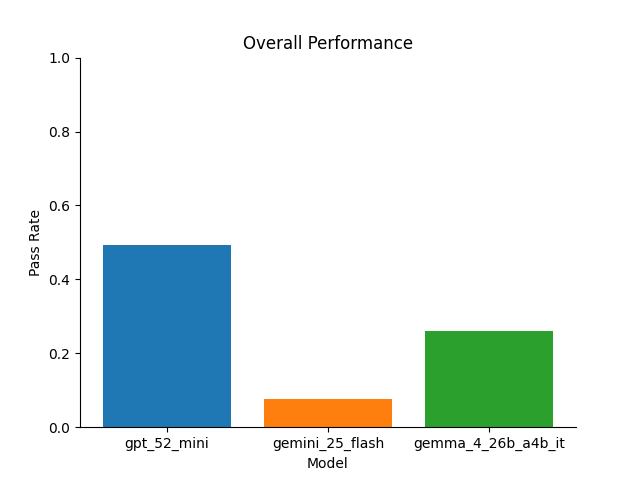

: 

In [ ]:
Image(filename='results/plot_overall.png') 

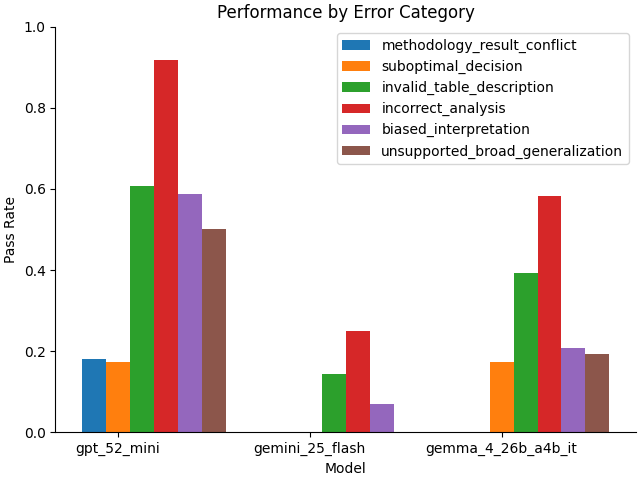

: 

In [ ]:
Image(filename='results/plot_by_error.png') 